In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [5]:
df = pd.read_csv("Wine.csv")

print("First five rows of the dataset:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())


First five rows of the dataset:
   Alcohol  Malic_Acid   Ash  Ash_Alcanity  Magnesium  Total_Phenols  \
0    14.23        1.71  2.43          15.6        127           2.80   
1    13.20        1.78  2.14          11.2        100           2.65   
2    13.16        2.36  2.67          18.6        101           2.80   
3    14.37        1.95  2.50          16.8        113           3.85   
4    13.24        2.59  2.87          21.0        118           2.80   

   Flavanoids  Nonflavanoid_Phenols  Proanthocyanins  Color_Intensity   Hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   OD280  Proline  Customer_Segment  
0   3.92     1065     

In [7]:
X = df.iloc[:, :-1]
y = df.iloc[:, -1]


In [9]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)


In [11]:
print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)

print(
    "\nTotal variance retained:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)



Explained variance ratio:
[0.36198848 0.1920749 ]

Total variance retained: 55.41 %


In [13]:
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)
pca_df["Class"] = y.to_numpy()

print("\nTransformed data:")
print(pca_df.head())



Transformed data:
        PC1       PC2  Class
0  3.316751  1.443463      1
1  2.209465 -0.333393      1
2  2.516740  1.031151      1
3  3.757066  2.756372      1
4  1.008908  0.869831      1


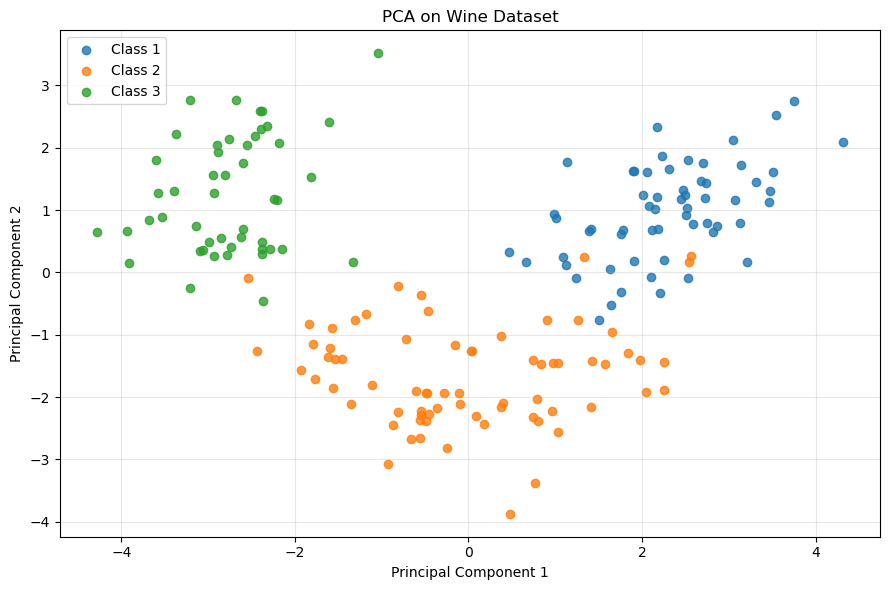

In [15]:
plt.figure(figsize=(9, 6))

for label in sorted(pca_df["Class"].unique()):
    subset = pca_df[pca_df["Class"] == label]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=f"Class {label}",
        alpha=0.8
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA on Wine Dataset")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
